# Lens Design Challenge — Polychromatic RMS spot minimisation

**Author:** Lorenzo Fratini

**Design:** Cooke triplet (N-LAK22 / N-SF5 / N-LAK22), spherical surfaces only, stop on the rear face of the flint element.

| Rule | Requirement |
|---|---|
| Object distance | Infinity |
| EFL | 50 mm ± 1 % |
| F-number | f/4 ± 2 % |
| Elements | 3 – 6, spherical only, catalog glasses |
| Stop | inside the optical system |
| BFD | ≥ 10 mm |
| Total track | ≤ 80 mm |
| Fields (semi-field) | 0°, 7°, 10°, 12°, 14° |
| Wavelengths | 0.486, 0.588, 0.656 µm, equal weights |
| Distortion | ≤ 2 % at every field |
| Center / edge thickness | ≥ 2 mm / ≥ 1 mm per element |

**Merit:** Σ (polychromatic RMS spot)² over the 5 fields **+ P**, where P = Σ (W·vᵢ)² has one term per rule (vᵢ = normalised violation, 0 when the rule is met).
The polychromatic RMS spot uses the rays of all three wavelengths about their **common centroid**, so lateral colour is included.

In [ ]:
#(needed on Google Colab)
%pip install -q optiland

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import optiland
from optiland.optic import Optic
from optiland.distribution import HexagonalDistribution
from optiland.optimization.operand.lens import LensOperand
from optiland.analysis import SpotDiagram, RmsSpotSizeVsField, Distortion



Optiland version: 0.6.2


## 1. Specification

In [3]:
EFL_TARGET, EFL_TOL = 50.0, 0.01      # +-1 %
FNO_TARGET, FNO_TOL = 4.0, 0.02       # +-2 %
BFD_MIN, TTL_MAX = 10.0, 80.0         # mm
DIST_MAX = 2.0                        # %
CT_MIN, ET_MIN = 2.0, 1.0             # mm
FIELDS_DEG = [0.0, 7.0, 10.0, 12.0, 14.0]
WAVELENGTHS = [0.486, 0.588, 0.656]   # um, equal weights
PRIMARY_WL = 0.588
PENALTY_WEIGHT = 1.0

## 2. Final design

Optimized lens, obtained with the optimisation in Section 6, starting from a classic Cooke triplet.

In [4]:
def build_final_design():
    lens = Optic(name="Cooke triplet N-LAK22 / N-SF5")
    crown, flint = ("N-LAK22", "schott"), ("N-SF5", "schott")
    lens.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
    lens.surfaces.add(index=1, radius=22.323703070555368, thickness=3.6489431577263907, material=crown)
    lens.surfaces.add(index=2, radius=-275.1959378104203, thickness=7.08962702457684)
    lens.surfaces.add(index=3, radius=-22.0614018338108, thickness=2.0082776001657763, material=flint)
    lens.surfaces.add(index=4, radius=20.472455381905007, thickness=4.995876299834361, is_stop=True)
    lens.surfaces.add(index=5, radius=78.57748392805985, thickness=2.835098398330519, material=crown)
    lens.surfaces.add(index=6, radius=-18.792117124791385, thickness=38.8305001444117)
    lens.surfaces.add(index=7)

    lens.set_aperture(aperture_type="imageFNO", value=FNO_TARGET)
    lens.fields.set_type("angle")
    for fy in FIELDS_DEG:
        lens.fields.add(y=fy)
    for wl in WAVELENGTHS:
        lens.wavelengths.add(value=wl, is_primary=(wl == PRIMARY_WL))
    return lens


lens = build_final_design()
lens.info()

╒════╤═════════════════╤═══════════╤═══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type            │ Comment   │    Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═════════════════╪═══════════╪═══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar          │           │  inf      │   inf       │ Air        │       0 │        10.0863  │
│  1 │ Standard        │           │   22.3237 │     3.64894 │ N-LAK22    │       0 │        10.0863  │
│  2 │ Standard        │           │ -275.196  │     7.08963 │ Air        │       0 │         8.88515 │
│  3 │ Standard        │           │  -22.0614 │     2.00828 │ N-SF5      │       0 │         4.88282 │
│  4 │ Stop - Standard │           │   20.4725 │     4.99588 │ Air        │       0 │         4.38377 │
│  5 │ Standard        │           │   78.5775 │     2.8351  │ N-LAK22    │       0 │         6.5781  │
│  6 │ Standard        │           │  -18.7921 │    38.8305  │ A

## 3. Metrics and penalty term P

In [5]:
def thicknesses(optic):
    z = np.asarray(optic.surfaces.positions).ravel()
    return np.diff(z[1:])                      # thickness after surface 1, 2, ...


def elements(optic):
    # (front, back) surface indices of every glass element
    out = []
    for i in range(1, optic.surfaces.num_surfaces - 1):
        if float(np.squeeze(optic.surfaces[i].material_post.n(PRIMARY_WL))) > 1.01:
            out.append((i, i + 1))
    return out


def spot_sizes(optic, rings=16):
    # Polychromatic RMS spot radius (mm) per field, about the common centroid of the 3 wavelengths
    dist = HexagonalDistribution()
    dist.generate_points(rings)
    px, py = np.asarray(dist.x), np.asarray(dist.y)
    nf, npup = len(FIELDS_DEG), len(px)
    Hy = np.repeat(np.array(FIELDS_DEG) / FIELDS_DEG[-1], npup)
    Px, Py = np.tile(px, nf), np.tile(py, nf)
    xs, ys = [], []
    for wl in WAVELENGTHS:
        rays = optic.trace_generic(np.zeros_like(Hy), Hy, Px, Py, wl)
        xs.append(np.asarray(rays.x).reshape(nf, npup))
        ys.append(np.asarray(rays.y).reshape(nf, npup))
    x, y = np.concatenate(xs, axis=1), np.concatenate(ys, axis=1)
    rms = np.sqrt(np.mean((x - x.mean(1, keepdims=True)) ** 2 + (y - y.mean(1, keepdims=True)) ** 2, axis=1))
    return np.where(np.isfinite(rms), rms, 10.0)


def distortions(optic, near_axis_deg=0.1):
    # Real chief-ray f-tan distortion (%); reference scale from a near-axis real chief ray
    angles = np.array([near_axis_deg] + FIELDS_DEG[1:])
    Hy = angles / FIELDS_DEG[-1]
    zeros = np.zeros_like(Hy)
    y = np.asarray(optic.trace_generic(zeros, Hy, zeros, zeros, PRIMARY_WL).y)
    tan = np.tan(np.radians(angles))
    scale = y[0] / tan[0]
    return [0.0] + list(100.0 * (y[1:] - scale * tan[1:]) / (scale * tan[1:]))


def system_values(optic):
    # Semi-apertures = |marginal| + |chief| paraxial ray height (Optiland convention);
    # refresh them so the edge thickness is measured on the current lens.
    optic.updater.update_paraxial()
    t = thicknesses(optic)
    efl = float(optic.paraxial.f2())
    elems = elements(optic)
    stop = optic.surfaces.stop_index
    return {
        "efl": efl,
        "fno": efl / float(optic.paraxial.EPD()),
        "bfd": float(t[-1]),
        "ttl": float(t.sum()),
        "dist": distortions(optic),
        "ct": [float(t[a - 1]) for a, _ in elems],
        "et": [float(np.squeeze(LensOperand.edge_thickness(optic, a))) for a, _ in elems],
        "n_elements": len(elems),
        "stop_inside": elems[0][0] <= stop <= elems[-1][1],
    }


def violations(optic, margin=None):
    # Normalised violation of every rule (0 = rule satisfied). `margin` tightens the limits during optimisation.
    m = margin or {"efl": 0, "fno": 0, "bfd": 0, "ttl": 0, "dist": 0, "et": 0}
    v = system_values(optic)
    return {
        "EFL": max(0.0, abs(v["efl"] / EFL_TARGET - 1) - (EFL_TOL - m["efl"])) / EFL_TOL,
        "F-number": max(0.0, abs(v["fno"] / FNO_TARGET - 1) - (FNO_TOL - m["fno"])) / FNO_TOL,
        "BFD": max(0.0, BFD_MIN + m["bfd"] - v["bfd"]) / BFD_MIN,
        "TTL": max(0.0, v["ttl"] - (TTL_MAX - m["ttl"])) / TTL_MAX,
        "Distortion": sum(max(0.0, abs(d) - (DIST_MAX - m["dist"])) for d in v["dist"]) / DIST_MAX,
        "Center thickness": sum(max(0.0, CT_MIN - t) for t in v["ct"]) / CT_MIN,
        "Edge thickness": sum(max(0.0, ET_MIN + m["et"] - t) for t in v["et"]) / ET_MIN,
        "Elements (3-6)": float(not 3 <= v["n_elements"] <= 6),
        "Stop inside system": float(not v["stop_inside"]),
    }


def penalty(optic, margin=None):
    # P = sum_i (W * v_i)^2  -- penalises every constraint violation
    return sum((PENALTY_WEIGHT * x) ** 2 for x in violations(optic, margin).values())

## 4. Results

In [6]:
spots_um = spot_sizes(lens) * 1e3
v = system_values(lens)

results = pd.DataFrame({
    "Field [deg]": FIELDS_DEG,
    "Polychromatic RMS spot [um]": spots_um,
    "Distortion [%]": v["dist"],
})
display(results.style.format({"Polychromatic RMS spot [um]": "{:.3f}", "Distortion [%]": "{:.3f}"}).hide(axis="index"))
print(f"Mean polychromatic RMS spot over the 5 fields: {spots_um.mean():.3f} um")

Field [deg],Polychromatic RMS spot [um],Distortion [%]
0.000000,4.598,0.000
7.000000,7.541,0.177
10.000000,10.800,0.373
12.000000,12.381,0.554
14.000000,16.214,0.782


Mean polychromatic RMS spot over the 5 fields: 10.307 um


In [7]:
max_dist = max(abs(d) for d in v["dist"])
checks = pd.DataFrame([
    ("EFL [mm]",                  f"{v['efl']:.3f}",      "49.5 - 50.5",  abs(v["efl"] / EFL_TARGET - 1) <= EFL_TOL),
    ("F-number",                  f"{v['fno']:.3f}",      "3.92 - 4.08",  abs(v["fno"] / FNO_TARGET - 1) <= FNO_TOL),
    ("Elements",                  f"{v['n_elements']}",   "3 - 6",        3 <= v["n_elements"] <= 6),
    ("Stop inside system",        f"{v['stop_inside']}",  "True",         v["stop_inside"]),
    ("BFD [mm]",                  f"{v['bfd']:.3f}",      ">= 10",        v["bfd"] >= BFD_MIN),
    ("Total track [mm]",          f"{v['ttl']:.3f}",      "<= 80",        v["ttl"] <= TTL_MAX),
    ("Max |distortion| [%]",      f"{max_dist:.3f}",      "<= 2",         max_dist <= DIST_MAX),
    ("Min center thickness [mm]", f"{min(v['ct']):.3f}",  ">= 2",         min(v["ct"]) >= CT_MIN),
    ("Min edge thickness [mm]",   f"{min(v['et']):.3f}",  ">= 1",         min(v["et"]) >= ET_MIN),
], columns=["Rule", "Value", "Limit", "OK"])
display(checks.style.hide(axis="index"))

P = penalty(lens)
score = float(np.sum((spots_um * 1e-3) ** 2)) + P
print(f"Penalty P = {P:.3e}")
print(f"Score = sum(RMS^2) + P = {score:.4e} mm^2")

Rule,Value,Limit,OK
EFL [mm],49.993,49.5 - 50.5,True
F-number,4.000,3.92 - 4.08,True
Elements,3,3 - 6,True
Stop inside system,True,True,True
BFD [mm],38.831,>= 10,True
Total track [mm],59.408,<= 80,True
Max |distortion| [%],0.782,<= 2,True
Min center thickness [mm],2.008,>= 2,True
Min edge thickness [mm],1.051,>= 1,True


Penalty P = 0.000e+00
Score = sum(RMS^2) + P = 6.1085e-04 mm^2


## 5. Visualisations

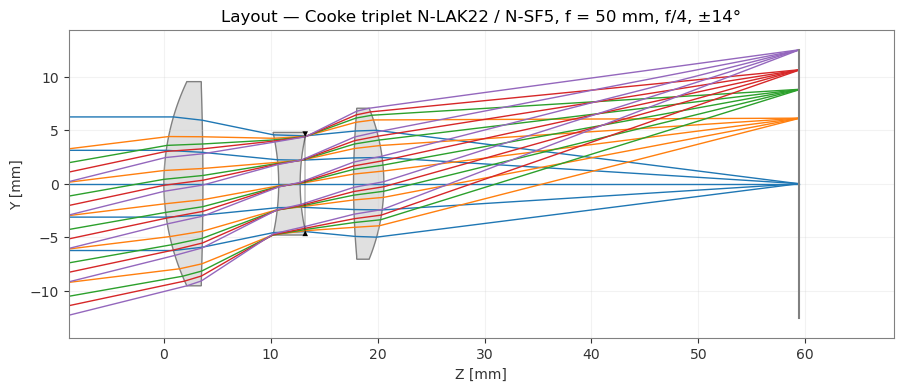

In [8]:
lens.draw(num_rays=5, figsize=(12, 4))
plt.title("Layout — Cooke triplet N-LAK22 / N-SF5, f = 50 mm, f/4, ±14°")
plt.show()

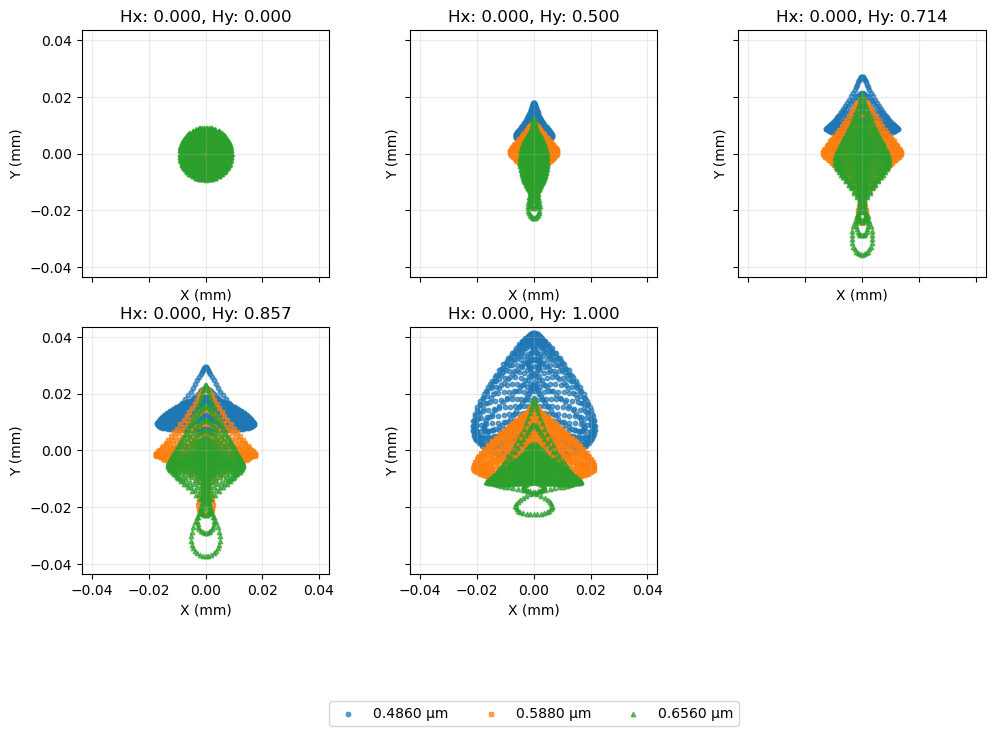

In [9]:
spot = SpotDiagram(lens, num_rings=16, reference="centroid")
spot.view()
plt.show()

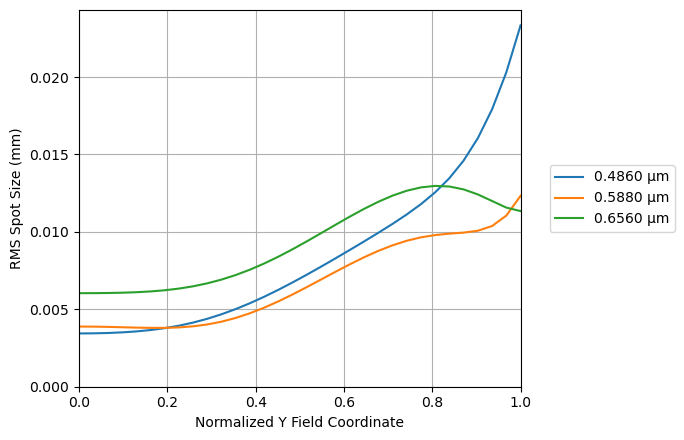

In [10]:
RmsSpotSizeVsField(lens, num_fields=32, num_rings=16).view()
plt.show()

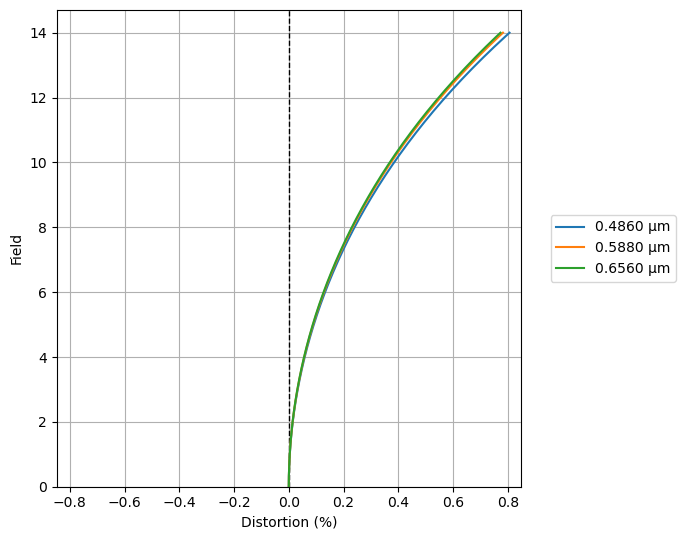

In [11]:
Distortion(lens).view()
plt.show()

## 6. Optimization

* **Start:** classic Cooke triplet (crown – flint – crown), stop on the rear face of the flint, f/4, scaled to f = 50 mm and made to respect CT ≥ 2 mm.
* **Variables:** all 6 radii, the 3 center thicknesses (≥ 2 mm), the 2 air spaces, and the BFD (≥ 10 mm).
* **Merit:** polychromatic RMS spot at the 5 fields + every term of P (with a small safety margin on the limits), and EFL = 50 mm target.
* **Optimiser:** `LeastSquares`
* **Glasses:** six crown/flint pairs were optimised; N-LAK22 / N-SF5 gave the lowest merit.
* **Final refinement:** the final design was improved, so that ET ≥ 1 mm holds.

Glass search (before the final refinement):

| Crown / Flint | Mean RMS (6-ring sampling) |
|---|---|
| **N-LAK22 / N-SF5** | **11.7 µm** |
| N-LAK9 / N-SF5 | 13.8 µm |
| N-SK16 / F2 | 16.4 µm |
| N-LAK9 / F2 | 17.2 µm |
| N-SSK8 / F2 | 28.6 µm |
| N-SK16 / N-SF5 | 34.1 µm |

The full search takes ~35 min, so it is switched off by default. Set `RUN_OPTIMIZATION = True` to re-run it for the winning glass pair (~7 min).

In [ ]:
RUN_OPTIMIZATION = False

import inspect
from optiland import optimization
from optiland.optimization.operand import operand_registry

MARGIN = {"efl": 0.004, "fno": 0.01, "bfd": 0.2, "ttl": 0.5, "dist": 0.1, "et": 0.05}
FIELD_IDX = list(range(len(FIELDS_DEG)))


def build_start_triplet(crown="N-LAK22", flint="N-SF5"):
    t = Optic(name=f"Cooke triplet {crown}/{flint}")
    c, f = (crown, "schott"), (flint, "schott")
    t.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
    t.surfaces.add(index=1, radius=22.01, thickness=3.5, material=c)
    t.surfaces.add(index=2, radius=-435.8, thickness=5.5)
    t.surfaces.add(index=3, radius=-22.21, thickness=2.0, material=f)
    t.surfaces.add(index=4, radius=20.29, thickness=4.5, is_stop=True)
    t.surfaces.add(index=5, radius=79.68, thickness=3.5, material=c)
    t.surfaces.add(index=6, radius=-18.40, thickness=41.0)
    t.surfaces.add(index=7)
    t.set_aperture(aperture_type="imageFNO", value=FNO_TARGET)
    t.fields.set_type("angle")
    for fy in FIELDS_DEG:
        t.fields.add(y=fy)
    for wl in WAVELENGTHS:
        t.wavelengths.add(value=wl, is_primary=(wl == PRIMARY_WL))
    return t


# Custom operands: polychromatic RMS at one field, and one P-term per rule
operand_registry.register("poly_rms_spot",
                          lambda optic, k: float(spot_sizes(optic, rings=6)[k]), overwrite=True)
operand_registry.register("constraint",
                          lambda optic, name: violations(optic, MARGIN)[name], overwrite=True)


# SciPy scales the variables from the Jacobian.
from optiland.optimization.optimizer.scipy import least_squares as _lsq_module
from scipy import optimize as _scipy_optimize
from types import SimpleNamespace
_accepts_cb = "callback" in inspect.signature(_scipy_optimize.least_squares).parameters

def _least_squares(*args, callback=None, **kwargs):
    if _accepts_cb:
        kwargs["callback"] = callback
    return _scipy_optimize.least_squares(*args, x_scale="jac", **kwargs)

_lsq_module.optimize = SimpleNamespace(least_squares=_least_squares)


def optimise(t, max_blocks=8, nfev_per_block=25, rel_tol=5e-3):
    problem = optimization.OptimizationProblem()
    for k in FIELD_IDX:
        problem.add_operand("poly_rms_spot", target=0.0, weight=1.0, input_data={"optic": t, "k": k})
    problem.add_operand("f2", target=EFL_TARGET, weight=0.1, input_data={"optic": t})
    for name in violations(t):
        problem.add_operand("constraint", target=0.0, weight=PENALTY_WEIGHT, input_data={"optic": t, "name": name})
    n = t.surfaces.num_surfaces
    for i in range(1, n - 1):
        problem.add_variable(t, "radius", surface_number=i)
    glass = {a for a, _ in elements(t)}
    for i in range(1, n - 2):
        lo, hi = (CT_MIN, 12.0) if i in glass else (0.5, 25.0)
        problem.add_variable(t, "thickness", surface_number=i, min_val=lo, max_val=hi)
    problem.add_variable(t, "thickness", surface_number=n - 2, min_val=BFD_MIN, max_val=60.0)

    merit = lambda: float(np.sum(spot_sizes(t, rings=6) ** 2)) + penalty(t, MARGIN)
    last = merit()
    for _ in range(max_blocks):
        optimization.LeastSquares(problem).optimize(maxiter=nfev_per_block, tol=1e-12, method_choice="trf")
        now = merit()
        print(f"  merit = {now:.4e}   mean RMS = {spot_sizes(t, rings=6).mean() * 1e3:.2f} um")
        if last - now < rel_tol * last:
            break
        last = now
    return t


if RUN_OPTIMIZATION:
    optimised = optimise(build_start_triplet("N-LAK22", "N-SF5"))
    print("Mean polychromatic RMS:", spot_sizes(optimised).mean() * 1e3, "um   P =", penalty(optimised))
else:
    print("Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.")

Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.
